# 01 — EDA del dataset (3 clases: Normal / Aggression / Theft)

Análisis exploratorio **solo de las clases que estudia la tesis**. El mapeo se lee de `configs/hr320_v2.yaml` (el mismo que usó `vad preprocess`):

| Clase | Categorías UCF-Crime |
|---|---|
| **Normal** | NormalVideos |
| **Aggression** | Assault, Abuse, Fighting |
| **Theft** | Robbery, Burglary, Stealing, Shoplifting |

Arson, Explosion, Vandalism, RoadAccidents, Arrest y Shooting **no se analizan**.

Cada video lleva un **estado** según `data/processed/ucf_crime_3class_320_v2`:
`train` / `val` / `test` (usados), `excluido_oscuro` / `excluido_corto` (filtro de calidad) o `no_seleccionado_tope` (sobra por el tope de Train).
Las estadísticas descriptivas se calculan sobre los **videos usados**; el filtro de calidad se muestra comparando usados vs. excluidos.

**Salidas**: `artifacts/eda_3class/`

## 0. Configuración

In [14]:
import json, re
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT_DIR = ROOT / "artifacts" / "eda_3class"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ── Mapeo de clases: se lee del MISMO yaml que usó `vad preprocess` ──────────
CONFIG = ROOT / "configs" / "hr320_v2.yaml"

DEFAULT_MAPPING = {                       # respaldo si no se puede leer el yaml
    "Normal":     ["NormalVideos"],
    "Aggression": ["Assault", "Abuse", "Fighting"],
    "Theft":      ["Robbery", "Burglary", "Stealing", "Shoplifting"],
}
PROC_DIR = ROOT / "data" / "processed" / "ucf_crime_3class_320_v2"
RAW_DIR = ROOT / "data" / "raw" / "ucf_crime_320"          # frames 320×240
VIDEOS_DIR = ROOT / "data" / "raw" / "ucf_crime_videos"    # mp4 originales
MIN_BRIGHTNESS = 30
CLASS_MAPPING, CLASS_TO_IDX = DEFAULT_MAPPING, None
try:
    import yaml
    _cfg = yaml.safe_load(CONFIG.read_text(encoding="utf-8"))
    CLASS_MAPPING = _cfg["preprocess"]["class_mapping"]
    CLASS_TO_IDX = _cfg["preprocess"].get("class_to_idx")
    MIN_BRIGHTNESS = _cfg["preprocess"].get("min_brightness", MIN_BRIGHTNESS)
    PROC_DIR = ROOT / _cfg["paths"]["processed_dir"]
    RAW_DIR = ROOT / _cfg["paths"]["raw_dir"]
    VIDEOS_DIR = ROOT / _cfg.get("videos", {}).get("dir", "data/raw/ucf_crime_videos")
    print("Config:", CONFIG.relative_to(ROOT))
except Exception as e:
    print(f"[AVISO] No se pudo leer {CONFIG} ({e}) → uso el mapeo por defecto")

CLASSES = sorted(CLASS_MAPPING, key=lambda c: CLASS_TO_IDX[c]) if CLASS_TO_IDX else list(CLASS_MAPPING)
CAT_TO_CLASS = {cat: cls for cls, cats in CLASS_MAPPING.items() for cat in cats}
COLORS = dict(zip(CLASSES, ["#4C72B0", "#C44E52", "#DD8452", "#55A868", "#8172B2"]))

print("Clases estudiadas:", CLASSES)
for c in CLASSES:
    print(f"  {c:<11} ← {', '.join(CLASS_MAPPING[c])}")
print("Todo lo demás (Arson, Explosion, Vandalism, RoadAccidents, Arrest, Shooting) queda FUERA del análisis.")

N_FRAMES = 16        # frames muestreados por video para brillo/color
WORKERS = 8
FPS_FRAMES = 30.0    # FPS de UCF-Crime (para videos analizados desde frames)

DARK_THR = float(MIN_BRIGHTNESS)  # mismo umbral del filtro de calidad
BRIGHT_THR = 200.0
MONO_SAT_THR = 12.0
MONO_CHAN_THR = 4.0
BLUR_THR = 50.0
LOW_CONTRAST_THR = 20.0

VIDEO_EXT = {".mp4", ".avi", ".mkv", ".mov", ".webm", ".mpg", ".mpeg", ".wmv", ".flv"}
USADOS = ["train", "val", "test"]

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 50)
for p in [PROC_DIR, RAW_DIR, VIDEOS_DIR]:
    print("OK " if p.exists() else "NO ", p)


Config: configs\hr320_v2.yaml
Clases estudiadas: ['Normal', 'Aggression', 'Theft']
  Normal      ← NormalVideos
  Aggression  ← Assault, Abuse, Fighting
  Theft       ← Robbery, Burglary, Stealing, Shoplifting
Todo lo demás (Arson, Explosion, Vandalism, RoadAccidents, Arrest, Shooting) queda FUERA del análisis.
OK  e:\deepl\MIA\data\processed\ucf_crime_3class_320_v2
OK  e:\deepl\MIA\data\raw\ucf_crime_320
OK  e:\deepl\MIA\data\raw\ucf_crime_videos


## 1. Videos de las 3 clases y su estado

In [15]:
def norm_key(s):
    """Clave de emparejamiento: nombre del video sin extensión, sin '_' ni mayúsculas."""
    return re.sub(r"[^a-z0-9]", "", Path(str(s).replace("\\", "/")).stem.lower())

splits = pd.concat([pd.read_json(f, lines=True).assign(split=f.stem)
                    for f in sorted((PROC_DIR / "splits").glob("*.jsonl"))], ignore_index=True)
exc = pd.read_csv(PROC_DIR / "excluded_videos.csv")
exc = exc[exc["ucf_category"].isin(CAT_TO_CLASS)]

registro = {}
for r in splits.to_dict("records"):
    registro[norm_key(r["video_id"])] = dict(video_id=r["video_id"], ucf_category=r["ucf_category"],
        clase=r["class_name"], estado=r["split"], brillo_filtro=r.get("brightness", np.nan))
for r in exc.to_dict("records"):
    registro.setdefault(norm_key(r["video_id"]), dict(video_id=r["video_id"], ucf_category=r["ucf_category"],
        clase=CAT_TO_CLASS[r["ucf_category"]], estado=f"excluido_{r['reason']}", brillo_filtro=r.get("brightness", np.nan)))


def categoria_ucf(p):
    if "normal" in p.parent.name.lower() or p.stem.lower().startswith("normal"):
        return "NormalVideos"
    if p.parent.name in CAT_TO_CLASS:
        return p.parent.name
    m = re.match(r"[A-Za-z]+", p.stem)
    return m.group(0) if m else p.parent.name


# Universo = mp4 originales cuya categoría pertenece a una de las 3 clases
items = []
mp4 = sorted(p for p in VIDEOS_DIR.rglob("*") if p.suffix.lower() in VIDEO_EXT) if VIDEOS_DIR.exists() else []
for p in mp4:
    cat = categoria_ucf(p)
    if cat not in CAT_TO_CLASS:
        continue                                   # categoría fuera del estudio
    k = norm_key(p)
    info = registro.get(k, dict(video_id=p.stem, ucf_category=cat, clase=CAT_TO_CLASS[cat],
                                estado="no_seleccionado_tope", brillo_filtro=np.nan))
    items.append(dict(key=k, path=str(p), tipo="video", **info))

# Videos de los splits/excluidos sin mp4 → se analizan desde sus frames 320×240
vistos = {it["key"] for it in items}
for k, info in registro.items():
    if k not in vistos:
        items.append(dict(key=k, path=None, tipo="frames", **info))

it_df = pd.DataFrame(items)
print(f"{len(it_df)} videos de las 3 clases | desde mp4: {(it_df.tipo == 'video').sum()} | desde frames: {(it_df.tipo == 'frames').sum()}")
display(pd.crosstab(it_df.clase, it_df.estado).reindex(CLASSES))


1500 videos de las 3 clases | desde mp4: 1500 | desde frames: 0


estado,excluido_oscuro,no_seleccionado_tope,test,train,val
clase,,,,,
Normal,3,597,150,160,40
Aggression,2,0,10,110,28
Theft,6,201,43,120,30


## 2. Extracción de metadatos y calidad visual

In [16]:
def frame_stats(fr):
    gray = cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(fr, cv2.COLOR_BGR2HSV)
    f = fr.astype(np.int16)
    chan_diff = (np.abs(f[..., 0] - f[..., 1]) + np.abs(f[..., 1] - f[..., 2]) + np.abs(f[..., 0] - f[..., 2])) / 3
    lit = hsv[..., 2] > 30
    return dict(brightness=gray.mean(), contrast=gray.std(),
                saturation=hsv[..., 1][lit].mean() if lit.any() else 0.0,
                chan_diff=chan_diff.mean(),
                pct_white=(gray >= 250).mean() * 100, pct_black=(gray <= 5).mean() * 100,
                sharpness=cv2.Laplacian(gray, cv2.CV_64F).var())


def _resize(fr, w=320):
    return cv2.resize(fr, (w, int(fr.shape[0] * w / fr.shape[1]))) if fr.shape[1] > w else fr


def analizar_video(path):
    p = Path(path)
    row = dict(size_mb=round(p.stat().st_size / 1e6, 3), corrupt=False)
    cap = cv2.VideoCapture(str(p))
    if not cap.isOpened():
        return {**row, "corrupt": True}
    fps = cap.get(cv2.CAP_PROP_FPS) or 0.0
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT) or 0)
    w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cc = int(cap.get(cv2.CAP_PROP_FOURCC))
    row.update(fps=round(fps, 2), n_frames=n, width=w, height=h,
               codec="".join(chr((cc >> 8 * i) & 0xFF) for i in range(4)).strip(),
               duration_s=n / fps if fps > 0 else np.nan)
    stats = []
    for i in np.unique(np.linspace(0, max(n - 1, 0), num=min(N_FRAMES, max(n, 1)), dtype=int)):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
        ok_, fr = cap.read()
        if ok_ and fr is not None:
            stats.append(frame_stats(_resize(fr)))
    cap.release()
    if not stats:
        return {**row, "corrupt": True}
    return {**row, **pd.DataFrame(stats).mean().to_dict()}


FRAME_RE = re.compile(r"^(.*)_(\d+)\.(jpg|jpeg|png)$", re.I)

def frames_de(video_id, cat):
    out = []
    for f in RAW_DIR.glob(f"*/{cat}/{video_id}_*"):
        m = FRAME_RE.match(f.name)
        if m and m.group(1) == video_id:
            out.append((int(m.group(2)), f))
    return [f for _, f in sorted(out)], (max(i for i, _ in out) + 1 if out else 0)


def analizar_frames(video_id, cat):
    imgs, n_orig = frames_de(video_id, cat)
    if not imgs:
        return dict(corrupt=True)
    first = cv2.imread(str(imgs[0]))
    if first is None:
        return dict(corrupt=True)
    idx = np.unique(np.linspace(0, len(imgs) - 1, num=min(N_FRAMES, len(imgs)), dtype=int))
    stats = [frame_stats(_resize(fr)) for fr in (cv2.imread(str(imgs[i])) for i in idx) if fr is not None]
    return dict(corrupt=False, fps=FPS_FRAMES, n_frames=n_orig, width=first.shape[1], height=first.shape[0],
                codec="jpg", duration_s=n_orig / FPS_FRAMES,
                size_mb=round(sum(f.stat().st_size for f in imgs) / 1e6, 3),
                **pd.DataFrame(stats).mean().to_dict())


def analizar(it):
    try:
        res = analizar_video(it["path"]) if it["tipo"] == "video" else analizar_frames(it["video_id"], it["ucf_category"])
    except Exception as e:
        res = dict(corrupt=True, error=str(e))
    return {**it, **res}


rows = []
with ThreadPoolExecutor(max_workers=WORKERS) as ex:
    futs = [ex.submit(analizar, it) for it in items]
    for k, fu in enumerate(as_completed(futs), 1):
        rows.append(fu.result())
        if k % 200 == 0 or k == len(futs):
            print(f"  {k}/{len(futs)}")

df = pd.DataFrame(rows)
df["clase"] = pd.Categorical(df["clase"], categories=CLASSES, ordered=True)
df = df.sort_values(["clase", "video_id"]).reset_index(drop=True)
df["usado"] = df["estado"].isin(USADOS)
ok = ~df["corrupt"]
df["resolution"] = df["width"].astype("Int64").astype(str) + "x" + df["height"].astype("Int64").astype(str)
df["aspect_ratio"] = (df["width"] / df["height"]).round(3)
df["orientation"] = np.select([df.width > df.height, df.height > df.width], ["horizontal", "vertical"], "cuadrado")
df["is_dark"] = ok & (df["brightness"] < DARK_THR)
df["is_bright"] = ok & (df["brightness"] > BRIGHT_THR)
df["is_monochrome"] = ok & ((df["saturation"] < MONO_SAT_THR) | (df["chan_diff"] < MONO_CHAN_THR))
df["is_blurry"] = ok & (df["sharpness"] < BLUR_THR)
df["is_low_contrast"] = ok & (df["contrast"] < LOW_CONTRAST_THR)

df.drop(columns=["key"]).to_csv(OUT_DIR / "video_metadata.csv", index=False)
v = df[df.usado & ok].copy()          # ← videos que realmente usa el modelo
print(f"Videos usados (train+val+test): {len(v)}")


  200/1500
  400/1500
  600/1500
  800/1500
  1000/1500
  1200/1500
  1400/1500
  1500/1500
Videos usados (train+val+test): 691


## 3. Distribución de clases

estado,train,val,test,excluido_oscuro,no_seleccionado_tope,disponibles,usados
clase,,,,,,,
Normal,160,40,150,3,597,950,350
Aggression,110,28,10,2,0,150,148
Theft,120,30,43,6,201,400,193
Total,390,98,203,11,798,1500,691


Ratio de desbalance en train (max/min): 1.45
Ratio de desbalance en test  (max/min): 15.0

Categorías UCF dentro de cada clase (videos usados):


clase,Normal,Aggression,Theft
ucf_category,,,
Abuse,0,49,0
Assault,0,49,0
Burglary,0,0,39
Fighting,0,50,0
NormalVideos,350,0,0
Robbery,0,0,71
Shoplifting,0,0,32
Stealing,0,0,51


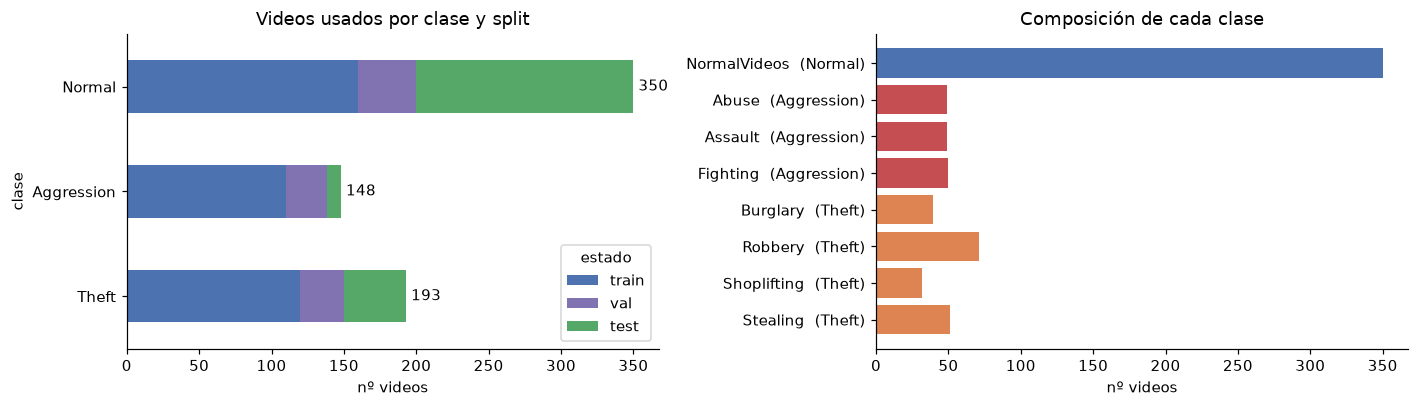

In [17]:
orden_estado = ["train", "val", "test", "excluido_oscuro", "excluido_corto", "no_seleccionado_tope"]
tabla = pd.crosstab(df["clase"], df["estado"])
tabla = tabla.reindex(index=CLASSES, columns=[c for c in orden_estado if c in tabla.columns]
                      + [c for c in tabla.columns if c not in orden_estado], fill_value=0)
tabla["disponibles"] = tabla.sum(axis=1)
tabla["usados"] = tabla[[c for c in USADOS if c in tabla]].sum(axis=1)
tabla.loc["Total"] = tabla.sum()
display(tabla)

tr = tabla.loc[CLASSES, "train"]
print(f"Ratio de desbalance en train (max/min): {tr.max() / tr.min():.2f}")
print(f"Ratio de desbalance en test  (max/min): {tabla.loc[CLASSES, 'test'].max() / tabla.loc[CLASSES, 'test'].min():.1f}")

print("\nCategorías UCF dentro de cada clase (videos usados):")
display(pd.crosstab(v["ucf_category"], v["clase"]).reindex(columns=CLASSES))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
tabla.loc[CLASSES, [c for c in USADOS if c in tabla]].plot.barh(stacked=True, ax=axes[0],
    color=["#4C72B0", "#8172B2", "#55A868"])
for i, c in enumerate(CLASSES):
    axes[0].text(tabla.loc[c, "usados"], i, f" {tabla.loc[c, 'usados']}", va="center")
axes[0].invert_yaxis(); axes[0].set_xlabel("nº videos"); axes[0].set_title("Videos usados por clase y split")

cat = v.groupby(["clase", "ucf_category"], observed=True).size().reset_index(name="n")
axes[1].barh(cat["ucf_category"] + "  (" + cat["clase"].astype(str) + ")", cat["n"],
             color=cat["clase"].map(COLORS))
axes[1].invert_yaxis(); axes[1].set_xlabel("nº videos"); axes[1].set_title("Composición de cada clase")
plt.tight_layout(); plt.savefig(OUT_DIR / "01_clases.png"); plt.show()


## 4. Duración — mínimo, máximo, media, mediana, moda

In [18]:
d = v["duration_s"].dropna()
moda_s = d.round(0).mode().iloc[0]
bins10 = (d // 10 * 10).astype(int)
moda_bin = bins10.mode().iloc[0]
dur = pd.Series({
    "mínimo (s)": d.min(), "máximo (s)": d.max(), "media (s)": d.mean(), "mediana (s)": d.median(),
    "moda (s, redondeada)": moda_s, "moda (intervalo 10 s)": f"{moda_bin}-{moda_bin + 10} s",
    "desv. estándar (s)": d.std(), "p05 (s)": d.quantile(.05), "p95 (s)": d.quantile(.95),
    "total (horas)": d.sum() / 3600,
    "video más corto": v.loc[d.idxmin(), "video_id"], "video más largo": v.loc[d.idxmax(), "video_id"],
}).to_frame("valor")
display(dur)
display(v.groupby("clase", observed=True)["duration_s"].describe().round(1))


,valor
mínimo (s),4.566667
máximo (s),20934.0
media (s),238.583068
mediana (s),79.3
"moda (s, redondeada)",60.0
moda (intervalo 10 s),30-40 s
desv. estándar (s),1063.604067
p05 (s),17.183333
p95 (s),604.633333
total (horas),45.794694


,count,mean,std,min,25%,50%,75%,max
clase,,,,,,,,
Normal,350.0,337.3,1480.6,7.0,35.9,67.7,153.3,20934.0
Aggression,148.0,129.9,158.4,4.6,43.8,84.0,146.5,1054.7
Theft,193.0,142.8,159.2,13.5,53.5,91.3,170.8,1355.2


C:\Users\Usuario\AppData\Local\Temp\ipykernel_9428\210556738.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = axes[1].boxplot([v.loc[v.clase == c, "duration_s"].dropna() for c in CLASSES], vert=False, patch_artist=True)


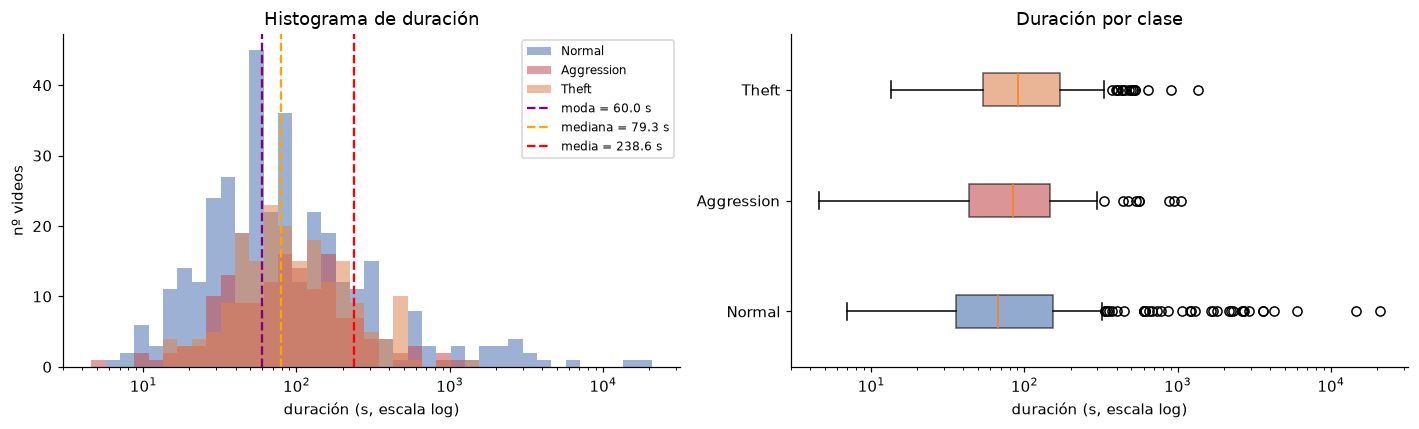

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bins = np.logspace(np.log10(max(d.min(), 0.1)), np.log10(d.max() + 1), 40)
for c in CLASSES:
    axes[0].hist(v.loc[v.clase == c, "duration_s"].dropna(), bins=bins, alpha=.55, label=c, color=COLORS[c])
for val, lab, col in [(moda_s, "moda", "purple"), (d.median(), "mediana", "orange"), (d.mean(), "media", "red")]:
    axes[0].axvline(val, ls="--", c=col, label=f"{lab} = {val:.1f} s")
axes[0].set_xscale("log"); axes[0].set_xlabel("duración (s, escala log)"); axes[0].set_ylabel("nº videos")
axes[0].set_title("Histograma de duración"); axes[0].legend(fontsize=8)
bp = axes[1].boxplot([v.loc[v.clase == c, "duration_s"].dropna() for c in CLASSES], vert=False, patch_artist=True)
for patch, c in zip(bp["boxes"], CLASSES):
    patch.set_facecolor(COLORS[c]); patch.set_alpha(.6)
axes[1].set_yticks(range(1, len(CLASSES) + 1), CLASSES)
axes[1].set_xscale("log"); axes[1].set_xlabel("duración (s, escala log)"); axes[1].set_title("Duración por clase")
plt.tight_layout(); plt.savefig(OUT_DIR / "02_duracion.png"); plt.show()


## 5. Resolución, FPS y tamaño — moda

,valor
resolución moda,320x240
orientación,{'horizontal': 691}
aspect ratio moda,1.333
FPS moda,30.0
FPS rango,25.0 - 30.0
"tamaño moda (MB, redondeado)",7.0
tamaño min / max (MB),0.53 / 5476.07
códec,"{'h264': 690, 'MJPG': 1}"


resolution,320x240
clase,
Normal,350
Aggression,148
Theft,193


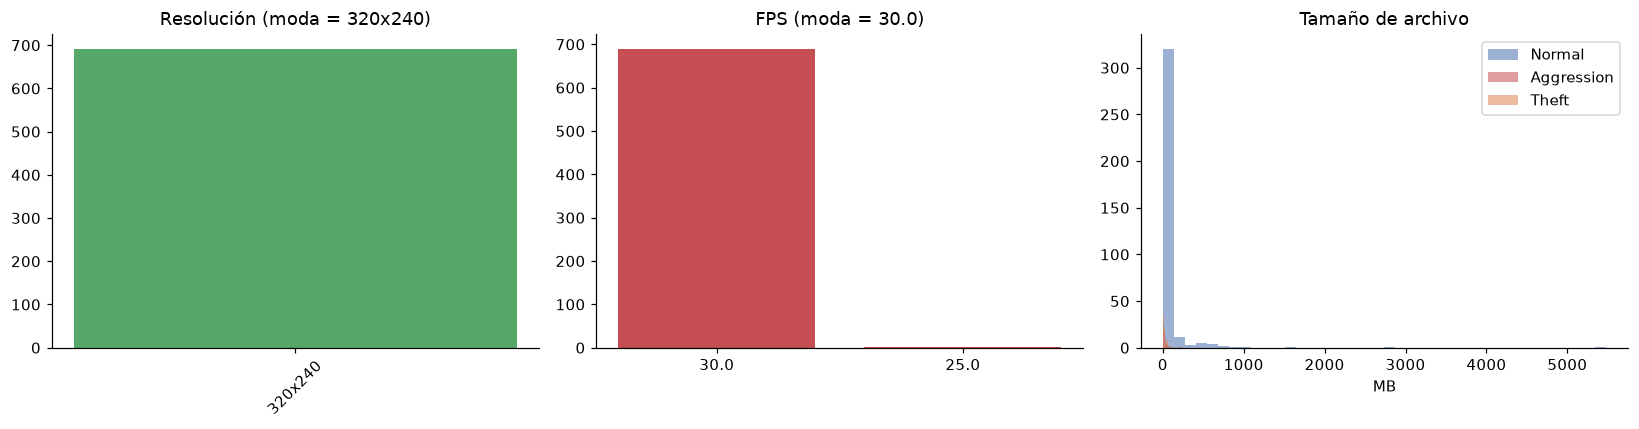

In [20]:
res = pd.Series({
    "resolución moda": v["resolution"].mode().iloc[0],
    "orientación": v["orientation"].value_counts().to_dict(),
    "aspect ratio moda": v["aspect_ratio"].mode().iloc[0],
    "FPS moda": v["fps"].mode().iloc[0],
    "FPS rango": f"{v['fps'].min()} - {v['fps'].max()}",
    "tamaño moda (MB, redondeado)": v["size_mb"].round(0).mode().iloc[0],
    "tamaño min / max (MB)": f"{v['size_mb'].min():.2f} / {v['size_mb'].max():.2f}",
    "códec": v["codec"].value_counts().to_dict(),
}).to_frame("valor")
display(res)
display(pd.crosstab(v["clase"], v["resolution"]))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
rc = v["resolution"].value_counts().head(10)
axes[0].bar(rc.index, rc.values, color="#55A868"); axes[0].tick_params(axis="x", rotation=45)
axes[0].set_title(f"Resolución (moda = {rc.index[0]})")
fc = v["fps"].value_counts().head(10)
axes[1].bar(fc.index.astype(str), fc.values, color="#C44E52"); axes[1].set_title(f"FPS (moda = {fc.index[0]})")
for c in CLASSES:
    axes[2].hist(v.loc[v.clase == c, "size_mb"], bins=40, alpha=.55, label=c, color=COLORS[c])
axes[2].set_xlabel("MB"); axes[2].set_title("Tamaño de archivo"); axes[2].legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "03_resolucion_fps_tamano.png"); plt.show()


## 6. Calidad visual de los videos usados

- **Monocromático**: saturación media HSV < `MONO_SAT_THR` **o** diferencia media entre canales RGB < `MONO_CHAN_THR` (B/N e IR nocturno).
- **Muy brillante**: brillo > `BRIGHT_THR`. **Borroso**: varianza del Laplaciano < `BLUR_THR`. **Bajo contraste**: desv. estándar de luma < `LOW_CONTRAST_THR`.

> El brillo de esta sección se mide sobre 16 frames del video original. El filtro oficial (sección 7) usa 5 frames 320×240, así que un video usado puede salir aquí ligeramente por debajo de 30.

In [21]:
calidad = pd.DataFrame({
    "videos": [v.is_monochrome.sum(), v.is_dark.sum(), v.is_bright.sum(), v.is_blurry.sum(), v.is_low_contrast.sum()],
}, index=["monocromáticos", f"oscuros (<{DARK_THR:.0f})", f"muy brillantes (>{BRIGHT_THR:.0f})", "borrosos", "bajo contraste"])
calidad["pct"] = (calidad.videos / len(v) * 100).round(1)
display(calidad)

por_clase = v.groupby("clase", observed=True).agg(n=("video_id", "count"), brillo_medio=("brightness", "mean"),
    contraste=("contrast", "mean"), nitidez=("sharpness", "median"),
    monocromaticos=("is_monochrome", "sum"), brillantes=("is_bright", "sum"), borrosos=("is_blurry", "sum")).round(1)
por_clase["%_mono"] = (por_clase.monocromaticos / por_clase.n * 100).round(1)
display(por_clase)


,videos,pct
monocromáticos,76,11.0
oscuros (<30),0,0.0
muy brillantes (>200),0,0.0
borrosos,0,0.0
bajo contraste,1,0.1


,n,brillo_medio,contraste,nitidez,monocromaticos,brillantes,borrosos,%_mono
clase,,,,,,,,
Normal,350,89.0,65.5,2213.3,11,0,0,3.1
Aggression,148,88.2,61.4,901.1,23,0,0,15.5
Theft,193,95.8,63.9,1805.4,42,0,0,21.8


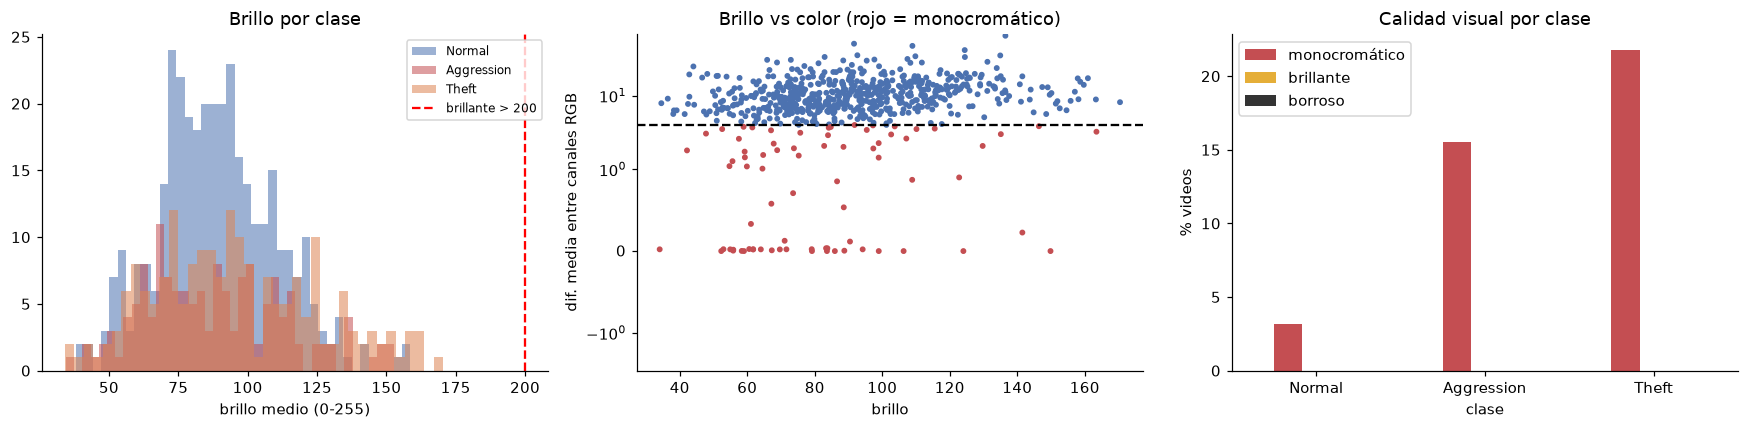

Monocromáticos (primeros 10):


,clase,ucf_category,video_id,estado,brightness,contrast,saturation,duration_s
158,Normal,NormalVideos,Normal_Videos187_x264,train,59.232083,45.985884,12.449667,299.966667
246,Normal,NormalVideos,Normal_Videos285_x264,train,83.351842,66.633273,0.239586,64.000000
341,Normal,NormalVideos,Normal_Videos388_x264,train,97.350421,65.902415,8.866157,143.633333
531,Normal,NormalVideos,Normal_Videos585_x264,val,61.507611,55.060903,22.851522,59.633333
802,Normal,NormalVideos,Normal_Videos_010_x264,test,52.296763,53.249448,0.000000,35.100000
810,Normal,NormalVideos,Normal_Videos_033_x264,test,110.137429,48.455705,12.587330,56.000000
826,Normal,NormalVideos,Normal_Videos_175_x264,test,47.776896,56.471398,24.094732,294.900000
900,Normal,NormalVideos,Normal_Videos_887_x264,test,64.022883,47.915002,0.203187,254.333333
924,Normal,NormalVideos,Normal_Videos_911_x264,test,103.685470,65.246273,14.436762,25.866667
931,Normal,NormalVideos,Normal_Videos_925_x264,test,94.193002,69.377434,0.121626,257.533333


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for c in CLASSES:
    axes[0].hist(v.loc[v.clase == c, "brightness"], bins=40, alpha=.55, label=c, color=COLORS[c])
axes[0].axvline(BRIGHT_THR, c="r", ls="--", label=f"brillante > {BRIGHT_THR:.0f}")
axes[0].set_xlabel("brillo medio (0-255)"); axes[0].set_title("Brillo por clase"); axes[0].legend(fontsize=8)

axes[1].scatter(v["brightness"], v["chan_diff"], s=8, c=v["is_monochrome"].map({True: "#C44E52", False: "#4C72B0"}))
axes[1].axhline(MONO_CHAN_THR, c="k", ls="--"); axes[1].set_yscale("symlog", linthresh=1)
axes[1].set_xlabel("brillo"); axes[1].set_ylabel("dif. media entre canales RGB")
axes[1].set_title("Brillo vs color (rojo = monocromático)")

(v.groupby("clase", observed=True)[["is_monochrome", "is_bright", "is_blurry"]].mean() * 100).plot.bar(
    ax=axes[2], color=["#C44E52", "#E5AE38", "#333333"])
axes[2].legend(["monocromático", "brillante", "borroso"]); axes[2].set_ylabel("% videos")
axes[2].set_title("Calidad visual por clase"); axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(OUT_DIR / "04_calidad_visual.png"); plt.show()

cols = ["clase", "ucf_category", "video_id", "estado", "brightness", "contrast", "saturation", "duration_s"]
for flag, nombre in [("is_monochrome", "monocromaticos"), ("is_bright", "brillantes"), ("is_blurry", "borrosos")]:
    v.loc[v[flag], cols].to_csv(OUT_DIR / f"lista_{nombre}.csv", index=False)
print("Monocromáticos (primeros 10):"); display(v.loc[v.is_monochrome, cols].head(10))


## 7. Filtro de calidad oficial: usados vs. excluidos

Se usa el **mismo brillo que calculó `vad preprocess`** (`brightness` en `splits/*.jsonl` y `excluded_videos.csv`: luma media sobre 5 frames). Por eso todos los excluidos por oscuridad quedan **a la izquierda del umbral**.

grupo,excluido_oscuro,usado
clase,,
Normal,3,350
Aggression,2,148
Theft,6,193


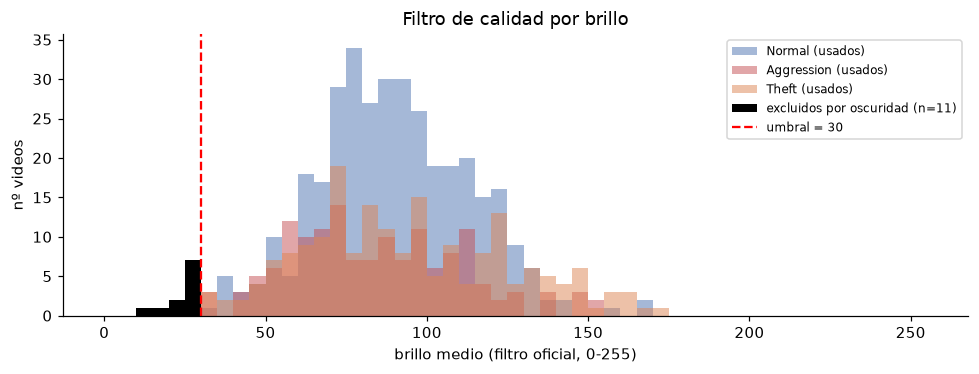

,clase,ucf_category,video_id,brillo_filtro
1418,Theft,Stealing,Stealing021_x264,14.6
640,Normal,NormalVideos,Normal_Videos705_x264,17.8
799,Normal,NormalVideos,Normal_Videos950_x264,22.6
728,Normal,NormalVideos,Normal_Videos806_x264,23.3
1254,Theft,Robbery,Robbery055_x264,25.0
1189,Theft,Burglary,Burglary090_x264,26.1
1496,Theft,Stealing,Stealing111_x264,26.4
981,Aggression,Abuse,Abuse032_x264,28.5
1283,Theft,Robbery,Robbery084_x264,29.2
1049,Aggression,Assault,Assault052_x264,29.2


In [23]:
filtro = df[df.usado | df.estado.str.startswith("excluido")].dropna(subset=["brillo_filtro"])
exc_osc = filtro[filtro.estado == "excluido_oscuro"]

resumen_filtro = filtro.assign(grupo=np.where(filtro.usado, "usado", filtro.estado)) \
    .groupby(["clase", "grupo"], observed=True).size().unstack(fill_value=0).reindex(CLASSES)
display(resumen_filtro)

fig, ax = plt.subplots(figsize=(9, 3.5))
bins = np.arange(0, 256, 5)
for c in CLASSES:
    ax.hist(filtro.loc[filtro.usado & (filtro.clase == c), "brillo_filtro"], bins=bins, alpha=.5, label=f"{c} (usados)", color=COLORS[c])
ax.hist(exc_osc["brillo_filtro"], bins=bins, color="black", label=f"excluidos por oscuridad (n={len(exc_osc)})")
ax.axvline(MIN_BRIGHTNESS, color="red", ls="--", label=f"umbral = {MIN_BRIGHTNESS}")
ax.set_xlabel("brillo medio (filtro oficial, 0-255)"); ax.set_ylabel("nº videos"); ax.legend(fontsize=8)
ax.set_title("Filtro de calidad por brillo")
plt.tight_layout(); plt.savefig(OUT_DIR / "05_filtro_brillo.png"); plt.show()

display(exc_osc[["clase", "ucf_category", "video_id", "brillo_filtro"]].sort_values("brillo_filtro"))


## 8. Inspección visual de muestras
Frame central de 4 videos usados por clase.

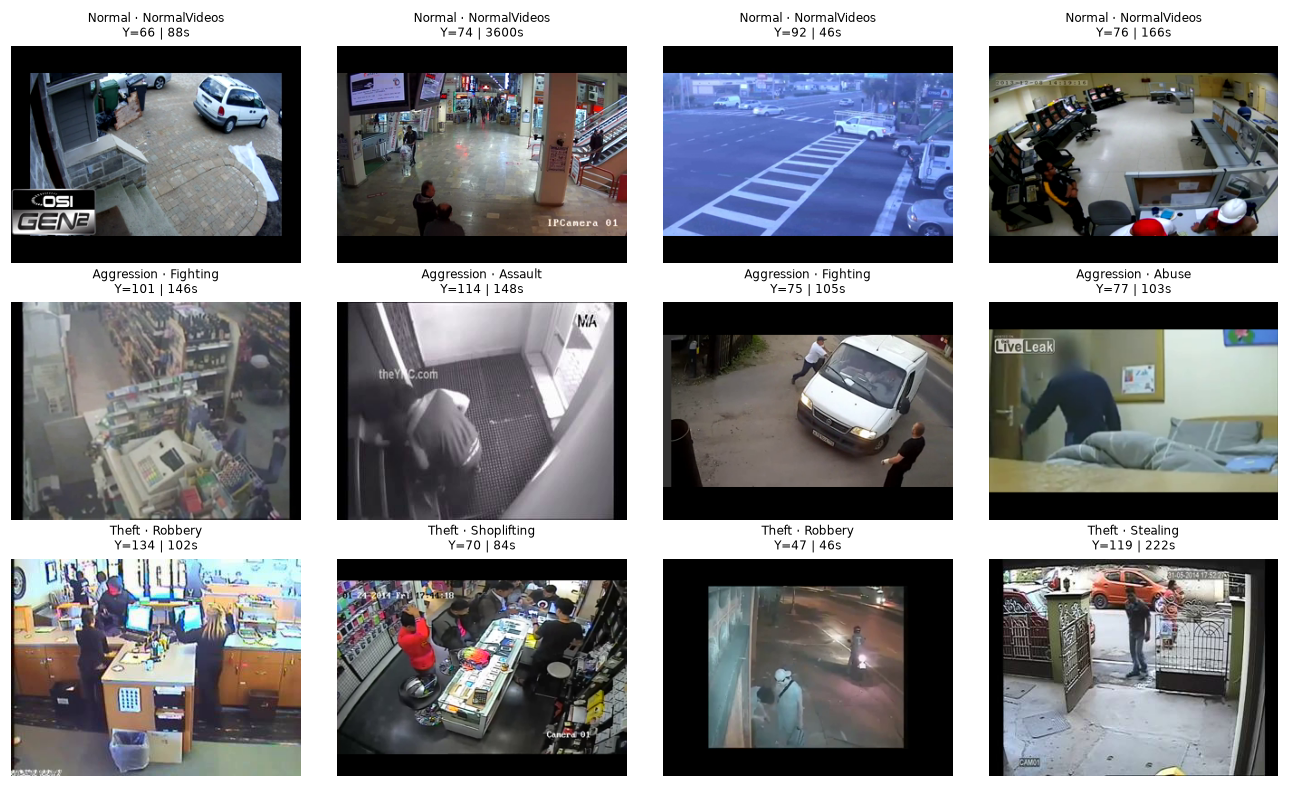

In [24]:
def frame_central(row):
    if row["tipo"] == "frames":
        imgs, _ = frames_de(row["video_id"], row["ucf_category"])
        return cv2.imread(str(imgs[len(imgs) // 2])) if imgs else None
    cap = cv2.VideoCapture(row["path"]); cap.set(cv2.CAP_PROP_POS_FRAMES, int(row["n_frames"]) // 2)
    ok_, fr = cap.read(); cap.release()
    return fr if ok_ else None

PER_CLASS = 4
fig, axes = plt.subplots(len(CLASSES), PER_CLASS, figsize=(3 * PER_CLASS, 2.4 * len(CLASSES)), squeeze=False)
for r, c in enumerate(CLASSES):
    sub = v[v.clase == c].sample(min(PER_CLASS, (v.clase == c).sum()), random_state=42)
    for k in range(PER_CLASS):
        ax = axes[r][k]; ax.axis("off")
        if k < len(sub):
            row = sub.iloc[k]; fr = frame_central(row)
            if fr is not None:
                ax.imshow(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB))
            ax.set_title(f"{c} · {row.ucf_category}{' [MONO]' if row.is_monochrome else ''}\n"
                         f"Y={row.brightness:.0f} | {row.duration_s:.0f}s", fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / "06_muestras.png", dpi=100); plt.show()


## 9. Videos corruptos / ilegibles

In [25]:
corruptos = df.loc[df.corrupt, ["clase", "ucf_category", "video_id", "estado"]]
corruptos.to_csv(OUT_DIR / "lista_corruptos.csv", index=False)
print(f"{len(corruptos)} corruptos")
corruptos


0 corruptos


,clase,ucf_category,video_id,estado


## 10. Resumen

In [26]:
resumen = {
    "clases": {c: CLASS_MAPPING[c] for c in CLASSES},
    "videos_disponibles": int(len(df)), "videos_usados": int(len(v)), "corruptos": int(df.corrupt.sum()),
    "por_clase_y_estado": {c: {k: int(x) for k, x in tabla.loc[c].items()} for c in CLASSES},
    "duracion_s": {k: (round(float(x), 2) if isinstance(x, (int, float, np.number)) else x) for k, x in dur["valor"].items()},
    "resolucion_moda": res.loc["resolución moda", "valor"], "fps_moda": float(res.loc["FPS moda", "valor"]),
    "calidad_usados": calidad["videos"].astype(int).to_dict(),
    "excluidos_oscuros": int(len(exc_osc)),
    "umbrales": dict(MIN_BRIGHTNESS=MIN_BRIGHTNESS, BRIGHT_THR=BRIGHT_THR, MONO_SAT_THR=MONO_SAT_THR,
                     MONO_CHAN_THR=MONO_CHAN_THR, BLUR_THR=BLUR_THR, LOW_CONTRAST_THR=LOW_CONTRAST_THR),
}
(OUT_DIR / "eda_resumen.json").write_text(json.dumps(resumen, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
resumen


{'clases': {'Normal': ['NormalVideos'],
  'Aggression': ['Assault', 'Abuse', 'Fighting'],
  'Theft': ['Robbery', 'Burglary', 'Stealing', 'Shoplifting']},
 'videos_disponibles': 1500,
 'videos_usados': 691,
 'corruptos': 0,
 'por_clase_y_estado': {'Normal': {'train': 160,
   'val': 40,
   'test': 150,
   'excluido_oscuro': 3,
   'no_seleccionado_tope': 597,
   'disponibles': 950,
   'usados': 350},
  'Aggression': {'train': 110,
   'val': 28,
   'test': 10,
   'excluido_oscuro': 2,
   'no_seleccionado_tope': 0,
   'disponibles': 150,
   'usados': 148},
  'Theft': {'train': 120,
   'val': 30,
   'test': 43,
   'excluido_oscuro': 6,
   'no_seleccionado_tope': 201,
   'disponibles': 400,
   'usados': 193}},
 'duracion_s': {'mínimo (s)': 4.57,
  'máximo (s)': 20934.0,
  'media (s)': 238.58,
  'mediana (s)': 79.3,
  'moda (s, redondeada)': 60.0,
  'moda (intervalo 10 s)': '30-40 s',
  'desv. estándar (s)': 1063.6,
  'p05 (s)': 17.18,
  'p95 (s)': 604.63,
  'total (horas)': 45.79,
  'video má

## 11. Conclusiones (completar con los resultados)

- **Clases**: se estudian Normal, Aggression y Theft; se excluyen Arson, Explosion y Vandalism por no corresponder a agresión ni robo (foco: asaltos).
- **Desbalance**: en train el ratio es … (tope 200/150/150); en test es … porque se conserva el test oficial completo (Aggression solo tiene … videos).
- **Duración**: moda … s, mediana … s, rango … – … s → L=16 segmentos por video.
- **Resolución / FPS**: moda … / … → frames redimensionados a 224×224.
- **Calidad**: …% monocromáticos (concentrados en …); … videos excluidos por brillo < 30.
- **Corruptos**: …